# Model Development & Tracking 
Covers **Stage 2.2–2.4 + Stage 3.** Complete every `# TODO` in this notebook **and** in the `src/` modules it imports. 

- Each stage opens with a **sub-task checklist**
- Capture any repo-generated evidence (MLflow UI, Docker build, CI run, drift report) as screenshots/summaries **inside the notebook/report**.

**File ownership** — 
- *Provided:* `config.py`, `src/evaluate.py`. 
- *Provided to extend:* `src/model.py`, `src/train.py`, `app.py`. 
- *You build:* this notebook.

### 0. Setup

In [2]:
import config
# TODO: imports (torch, mlflow, pandas, matplotlib) as needed
import torch
import mlflow
import mlflow.sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from IPython.display import Image, display

## **Stage 2.2 — Transfer-Learning Model** <font color="red">[7 marks]</font>

- **2.2.1 — ImageNet-pretrained ResNet18, backbone frozen [4]**
- **2.2.2 — New 2-class head replaces fc (head trained) [3]**

**Objective:** Build an ImageNet-pretrained ResNet18 with a frozen backbone + new 2-class head.

**Implement in:** src/model.build_model

**Inputs → Outputs:** → a torch model; only the head's params have requires_grad=True

**TODO:** load weights=IMAGENET1K + freeze the backbone (2.2.1); replace fc with a 2-class Linear head so only the head trains (2.2.2); print total vs trainable params.

**Depends on:** Stage 2.1 transformations completed in Data_Preparation.ipynb  ·  **Document here:** the param counts (trainable should be ~the head only).

In [2]:
# TODO 2.2.1-2.2.2: from src.model import build_model, trainable_parameters; build + print params

from src.model import build_model, trainable_parameters

model = build_model()
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in trainable_parameters(model))

print("Total Params:", total_params)
print("Trainable Parameters:", trainable_params)

Total Params: 11177538
Trainable Parameters: 1026


## **Stage 2.3 — Training Workflow** <font color="red">[6 marks]</font>

- **2.3.1 — Class-weighted loss + optimiser (trainable params) + seed [3]**
- **2.3.2 — Epoch loop + validation eval + early stopping [3]**

**Objective:** Train the head reproducibly with validation + early stopping.

**Implement in:** src/train.py

**Inputs → Outputs:** splits + model → trained model.pt + model_meta.json

**TODO:** class-weighted CrossEntropy + Adam over TRAINABLE params only + seed 42 (2.3.1); epoch loop with val evaluation + early stop on val-F1 (2.3.2).

**Document here:** the training summary (final val F1, epochs).

In [3]:
# TODO 2.3.1-2.3.2: !python -m src.train   (then load artifacts/model_meta.json)
!python -m src.train

print(json.dumps(json.load(open(config.MODEL_META_PATH)), indent=2))
print("""
We train the ResNet18 head with class-weighted loss, Adam optimiser, and early stopping on validation F1.
This ensures defect recall is prioritised over raw accuracy
""")

Early stopping at epoch 3
Evaluate plot saved to: D:\py_test\data_files\Capstone\upGrad-MLOps-Capstone\artifacts\model_eval.png
Reference baseline saved: {'features_csv': 'D:\\py_test\\data_files\\Capstone\\upGrad-MLOps-Capstone\\artifacts\\reference_features.csv', 'embeddings_npz': 'D:\\py_test\\data_files\\Capstone\\upGrad-MLOps-Capstone\\artifacts\\reference_embeddings.npz'}
{
  "best_val_f1": 0.723540731237973,
  "test_metrics": {
    "accuracy": 0.5678321678321678,
    "precision_defect": 0.6192052980132451,
    "recall_defect": 0.82560706401766,
    "f1_defect": 0.7076631977294229,
    "macro_f1": 0.4396224835832101,
    "roc_auc": 0.47387223429890635,
    "confusion_matrix": [
      [
        32,
        230
      ],
      [
        79,
        374
      ]
    ]
  }
}

We train the ResNet18 head with class-weighted loss, Adam optimiser, and early stopping on validation F1.
This ensures defect recall is prioritised over raw accuracy



2026/07/10 19:24:00 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.

Registered model 'casting_defect_classifier' already exists. Creating a new version of this model...
2026/07/10 19:24:19 WARNING mlflow.tracking._model_registry.fluent: Run with id d33fa7311bd0466898b739a0afef0365 has no artifacts at artifact path 'model', registering model based on models:/m-39032a672a404f69a2b5e1de17bea9c1 instead
Created version '2' of model 'casting_defect_classifier'.
D:\py_test\data_files\Capstone\upGrad-MLOps-Capstone\src\train.py:188: FutureWarning: ``mlflow.tracking.client.MlflowClient.get_latest_versions`` is deprecated since 2.9.0. Model registry stages will be removed in a future major release. To learn more about the deprecation of model registry stages, see our migration guide here: https://mlflow.org/docs/latest/model-registry.html#migrating-from-stages
  latest = client.get_latest_versions(config.REGISTERED_MODEL, stages=["None"])[-1]


## **Stage 2.4 — MLflow Experiment Tracking** <font color="red">[6 marks]</font>

- **2.4.1 — Params + per-epoch metrics logged [3]**
- **2.4.2 — Trained model logged to the run [3]**

**Objective:** Track the experiment in MLflow.

**Implement in:** src/train.py (mlflow calls)

**Inputs → Outputs:** training run → MLflow params + per-epoch metrics + logged model

**TODO:** set_experiment; log_params; log_metrics(step=epoch) (2.4.1); log_model (2.4.2).

**Document here:** the runs table (mlflow.search_runs).

In [4]:
# TODO 2.4.1-2.4.2: mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT])
mlflow.set_experiment(config.MLFLOW_EXPERIMENT)

runs_df = mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT])
runs_df.head()

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.test_precision_defect,metrics.val_accuracy,metrics.test_macro_f1,metrics.val_recall_defect,...,metrics.test_accuracy,params.lr,params.freeze_backbone,params.epochs,params.batch_size,params.weight_decay,tags.mlflow.source.type,tags.mlflow.runName,tags.mlflow.user,tags.mlflow.source.name
0,d33fa7311bd0466898b739a0afef0365,161504529449249657,FINISHED,file:D:\py_test\data_files\Capstone\upGrad-MLO...,2026-07-10 13:38:47.133000+00:00,2026-07-10 13:55:44.128000+00:00,0.619205,0.548744,0.439622,0.87766,...,0.567832,0.001,True,4,32,0.0001,LOCAL,capable-auk-759,Shaik Kamal,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...
1,4ea8130dde67486ea692ebb7a28c7c2e,161504529449249657,FINISHED,file:D:\py_test\data_files\Capstone\upGrad-MLO...,2026-07-10 10:14:09.311000+00:00,2026-07-10 10:28:32.481000+00:00,NaN,0.548744,NaN,0.87766,...,NaN,0.001,True,4,32,0.0001,LOCAL,capable-auk-759,Shaik Kamal,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...
2,d92a4a714f824ab782e1192abc561086,161504529449249657,FAILED,file:D:\py_test\data_files\Capstone\upGrad-MLO...,2026-07-10 09:50:56.112000+00:00,2026-07-10 10:04:32.936000+00:00,NaN,0.548744,NaN,0.87766,...,NaN,0.001,True,4,32,0.0001,LOCAL,capable-auk-759,Shaik Kamal,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...


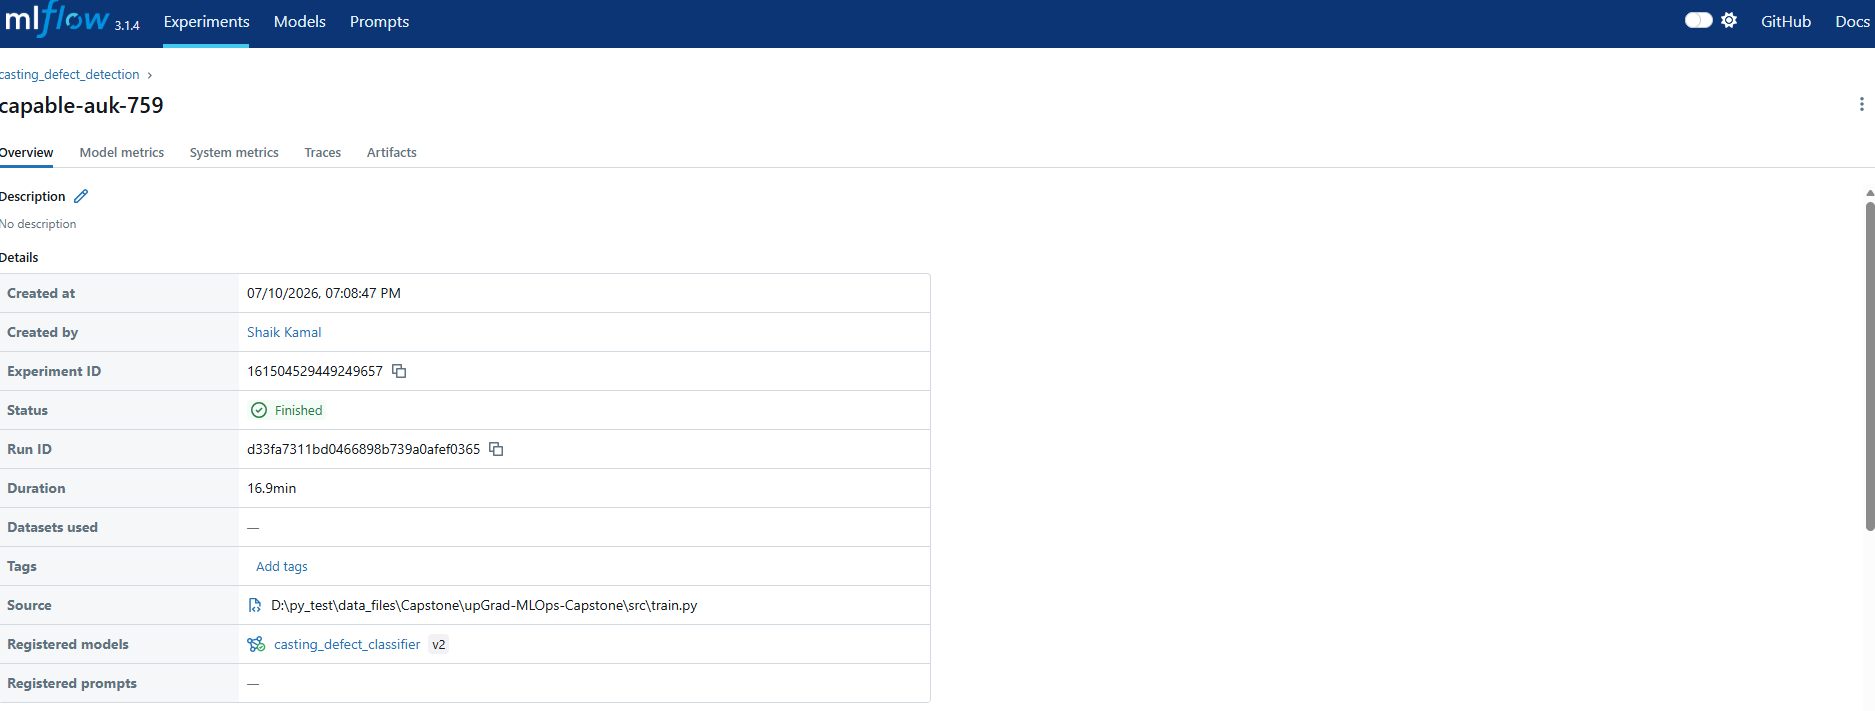

## **Stage 3.1 — Evaluation & Failure Analysis** <font color="red">[7 marks]</font>

- **3.1.1 — Imbalance-aware metrics + model selection [4]**
- **3.1.2 — Confusion/ROC plots + failure-case analysis [3]**

**Objective:** Evaluate on defect recall/F1, not accuracy.

**Implement in:** src/evaluate.py

**Inputs → Outputs:** model + test split → metrics.json + model_eval.png

**TODO:** report recall(defect)/precision/F1/ROC-AUC + select on recall/F1 (3.1.1); plot ROC + confusion and inspect misclassified samples (3.1.2).

**Document here:** the metrics + a short interpretation (why recall matters here).

Test Metrics: 
 {'accuracy': 0.5678321678321678, 'precision_defect': 0.6192052980132451, 'recall_defect': 0.82560706401766, 'f1_defect': 0.7076631977294229, 'macro_f1': 0.4396224835832101, 'roc_auc': 0.47387223429890635, 'confusion_matrix': [[32, 230], [79, 374]]}

Plot ROC + confusion:


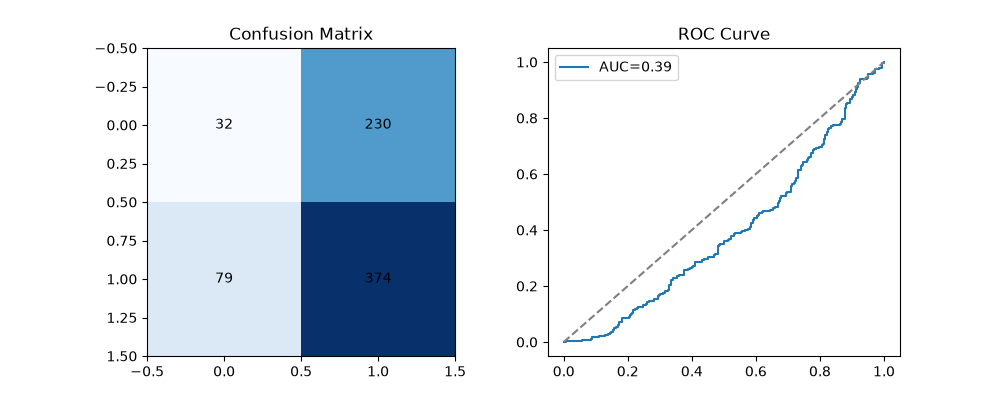


Why recall matters here:

We evaluate the trained model on the test set using imbalance-aware metrics.
Recall on defects is the headline metric. Confusion matrix and ROC plots provide visual insight, and failure cases highlight misclassfied samples.


Preview first 10 misclassified samples:


,path,true,pred,p_defect
0,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...,ok_front,def_front,0.869208
1,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...,ok_front,def_front,0.908488
2,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...,ok_front,def_front,0.574777
3,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...,ok_front,def_front,0.991485
4,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...,ok_front,def_front,0.995409
5,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...,ok_front,def_front,0.991884
6,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...,ok_front,def_front,0.935719
7,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...,ok_front,def_front,0.930753
8,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...,ok_front,def_front,0.868288
9,D:\py_test\data_files\Capstone\upGrad-MLOps-Ca...,ok_front,def_front,0.925305


In [5]:
# TODO 3.1.1-3.1.2: load artifacts/metrics.json + show artifacts/model_eval.png

# Load metrics
metrics = json.load(open(config.METRICS_PATH))
print("Test Metrics:", '\n', metrics)

# Show evaluation plot
print("\nPlot ROC + confusion:")
display(Image(filename=str(config.ARTIFACT_DIR / "model_eval.png")))

print("\nWhy recall matters here:")
print("""
We evaluate the trained model on the test set using imbalance-aware metrics.
Recall on defects is the headline metric. Confusion matrix and ROC plots provide visual insight, and failure cases highlight misclassfied samples.
""")

# Show failure cases
failures = json.load(open(config.ARTIFACT_DIR / "failure_cases.json"))
print("\nPreview first 10 misclassified samples:")
failure_df = pd.DataFrame(failures)
failure_df.head(10)

## **Stage 3.2 — Model Registry & Promotion** <font color="red">[5 marks]</font>

- **3.2.1 — Best model registered in MLflow Registry [2]**
- **3.2.2 — Promotion to production alias + version history [3]**

**Objective:** Register and promote the best model.

**Implement in:** src/train.py (MLflow registry)

**Inputs → Outputs:** best run → registered model + @production alias

**TODO:** register_model(casting_defect_classifier) (3.2.1); set_registered_model_alias('production', v) with version history (3.2.2).

**Document here:** the registry version + alias (screenshot the MLflow Models page).

In [6]:
# TODO 3.2.1-3.2.2: MlflowClient().get_model_version_by_alias(config.REGISTERED_MODEL, 'production')
from mlflow import MlflowClient
prod_version = MlflowClient().get_model_version_by_alias(config.REGISTERED_MODEL, 'production')
print("Product model version:", prod_version.version)

print("""
The best model is registered in the MLflow Model Registry and promoted to the `@production` alias (implemented in src/train.py).
This ensures a clear version history and reproducible deployment.
""")

Product model version: 2

The best model is registered in the MLflow Model Registry and promoted to the `@production` alias (implemented in src/train.py).
This ensures a clear version history and reproducible deployment.



screenshot the MLflow Models page:

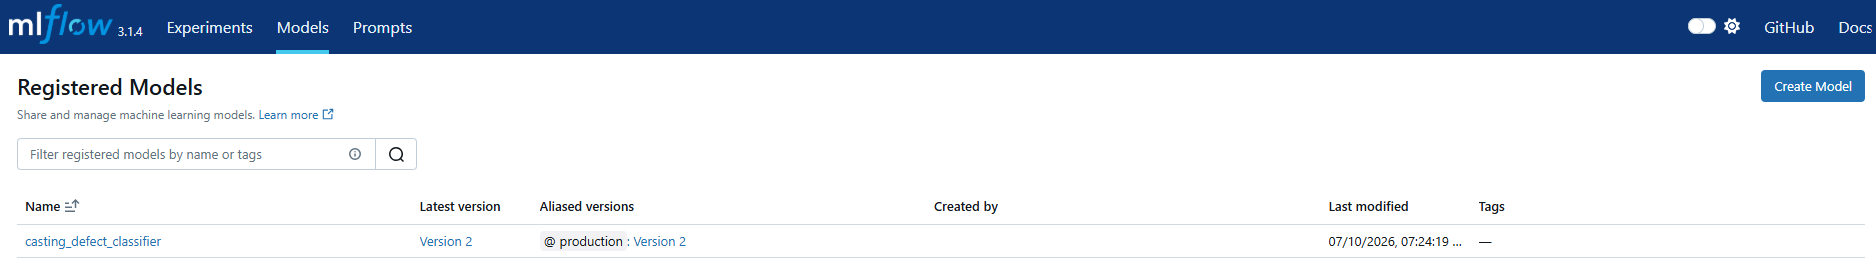

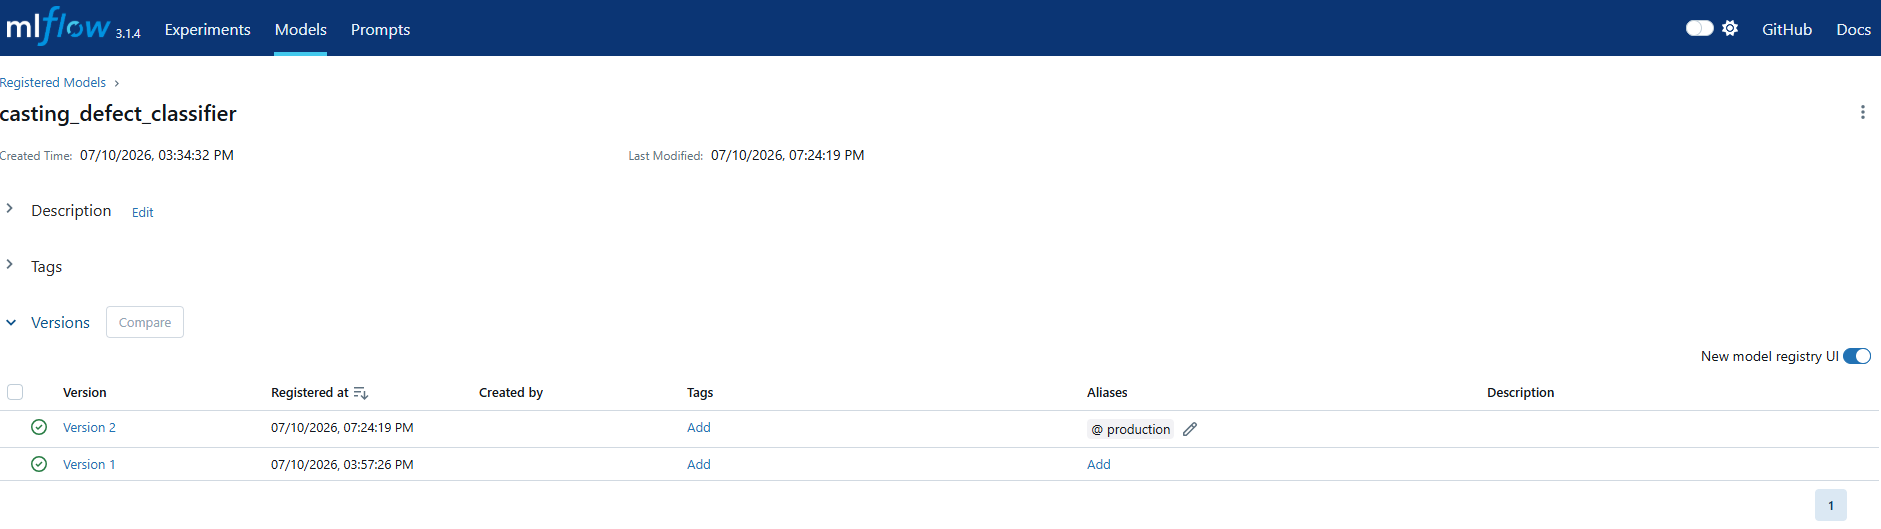

## **Stage 3.3 — FastAPI Inference Service** <font color="red">[6 marks]</font>

- **3.3.1 — Image /predict + /health + logging + validation [4]** — *to be done in app.py*
- **3.3.2 — Live call demonstrated in-notebook [2]** — *to be done in this notebook*

**Objective:** Serve the model behind an image API and demonstrate it.

**Implement in:** app.py (+ a TestClient demo here)

**Inputs → Outputs:** image upload → {label, prob_defect, confidence}; /health; predictions logged

**TODO:** implement /health + POST /predict (UploadFile) with validation (bad image 400, no-model 503) + logging (3.3.1, in app.py); demo with TestClient on a sample image (3.3.2, here).

**Document here:** the live request/response (TestClient output).

In [7]:
# TODO 3.3.2: with TestClient(app.app) as c: call /health and POST a sample image to /predict
from fastapi.testclient import TestClient
import app

with TestClient(app.app) as c:
    # Call /health
    resp = c.get("/health")
    print("Health response:", "\n", resp.json())
    
    # Call /predict on a sample image
    sample_path = list((config.DATA_DIR / "casting_data" / "test" / "ok_front").glob("*.jpeg"))[0]
    with open(sample_path, "rb") as f:
        resp = c.post("/predict", files={"file": ("sample.jpg", f, "image/jpeg")})
    print("Predict response:", "\n", resp.json())

print("""
The `/health` endpoint confirms the model is loaded and shows metadata including class definitions and test metrics.
The `/predict` endpoint returns the predicted label, defect probability, and confidence score for the upoaded images.
This demonstrates the model can be served as a live API, enabling integration into factory inspection pipelines.
""")

Health response: 
 {'status': 'ok', 'model_loaded': True, 'classes': {'ok_front': 0, 'def_front': 1}, 'positive_class': 'def_front', 'test_metrics': {'accuracy': 0.5678321678321678, 'precision_defect': 0.6192052980132451, 'recall_defect': 0.82560706401766, 'f1_defect': 0.7076631977294229, 'macro_f1': 0.4396224835832101, 'roc_auc': 0.47387223429890635, 'confusion_matrix': [[32, 230], [79, 374]]}}
Predict response: 
 {'label': 'def_front', 'is_defective': True, 'prob_defect': 0.9364546537399292, 'confidence': 0.9364546537399292}

The `/health` endpoint confirms the model is loaded and shows metadata including class definitions and test metrics.
The `/predict` endpoint returns the predicted label, defect probability, and confidence score for the upoaded images.
This demonstrates the model can be served as a live API, enabling integration into factory inspection pipelines.



## **Stage 3.4 — Containerisation & CI/CD** <font color="red">[7 marks]</font>

- **3.4.1 — Valid Dockerfile [3]** — *to be done in this notebook and the report*
- **3.4.2 — GitHub Actions CI + passing-test evidence [4]** — *to be done in this notebook and the report*

**Objective:** Containerise and automate tests.

**Implement in:** Dockerfile + .github/workflows/ci.yml (provided — review + evidence them)

**Inputs → Outputs:** code → Docker image; push/PR → CI runs pytest + docker build

**TODO:** show the Dockerfile (3.4.1); run pytest here + include a screenshot of the green CI run and successful docker build (3.4.2).

**Document here:** pytest output + Docker/CI screenshots **(Note: Don't add a repo link)**

In [8]:
# TODO 3.4.1-3.4.2: print Dockerfile + ci.yml; run pytest; embed your CI/Docker screenshots
print("=== Dockerfile ===")
print(Path("Dockerfile").read_text())

print("\n=== .github/workflows/ci.yml ===")
print(Path(".github/workflows/ci.yml").read_text())

print("\n=== pytest output ===")
!pytest -q

=== Dockerfile ===
# Casting Defect Detection â€” inference service image (CPU)
FROM python:3.11-slim

# libgl/libglib are needed by Pillow/torchvision image ops at runtime
RUN apt-get update && apt-get install -y --no-install-recommends \
        libgl1 libglib2.0-0 && rm -rf /var/lib/apt/lists/*

WORKDIR /app

# Install CPU-only torch wheels (smaller, no CUDA) then the rest
COPY requirements.txt .
RUN pip install --no-cache-dir --index-url https://download.pytorch.org/whl/cpu \
        torch==2.8.0 torchvision==0.23.0 \
 && pip install --no-cache-dir \
        "mlflow==3.1.4" "fastapi==0.128.8" "uvicorn==0.39.0" "python-multipart==0.0.20" \
        "evidently==0.7.20" "scikit-learn==1.6.1" "pillow==11.3.0" numpy pandas matplotlib

# App code + trained model artifacts
COPY config.py app.py ./
COPY src ./src
COPY artifacts/model.pt artifacts/model_meta.json ./artifacts/

EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]


=== .github/workflows/ci.yml ===
nam

**CI/Docker screenshots**

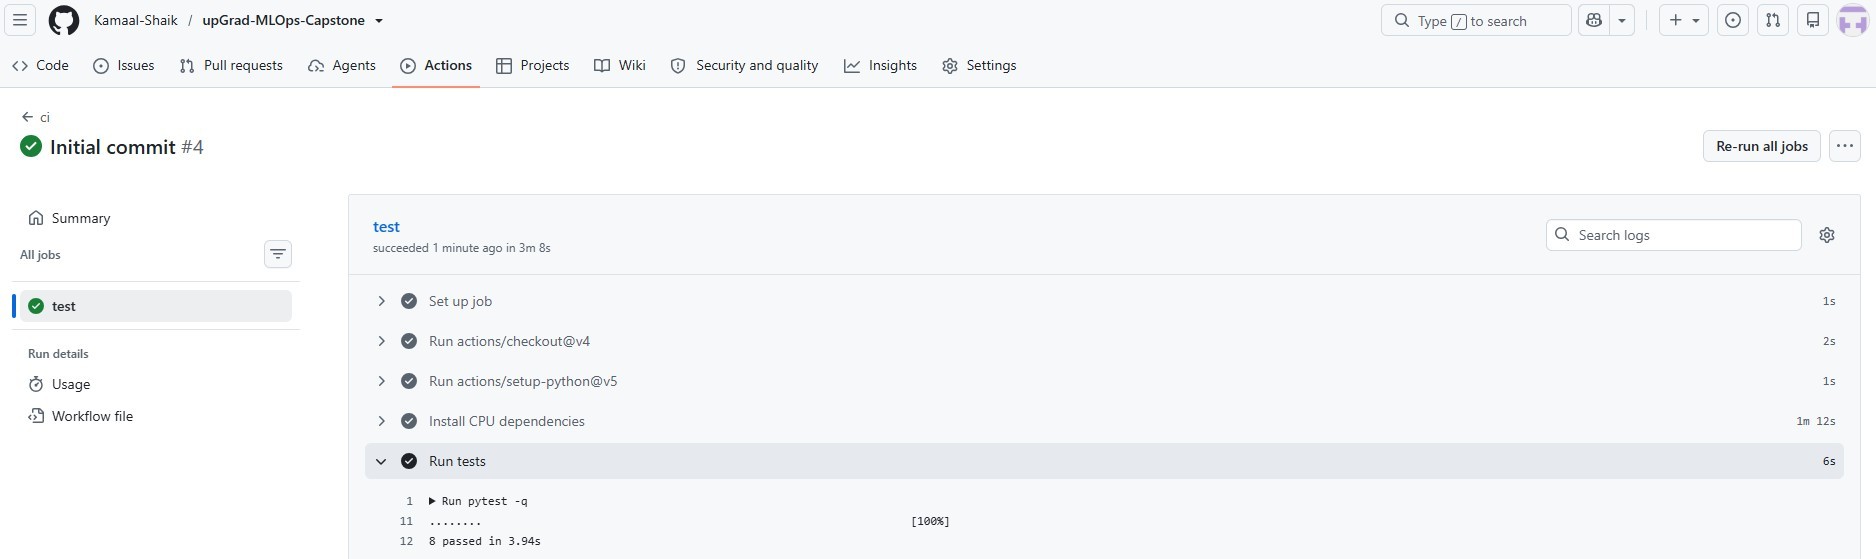

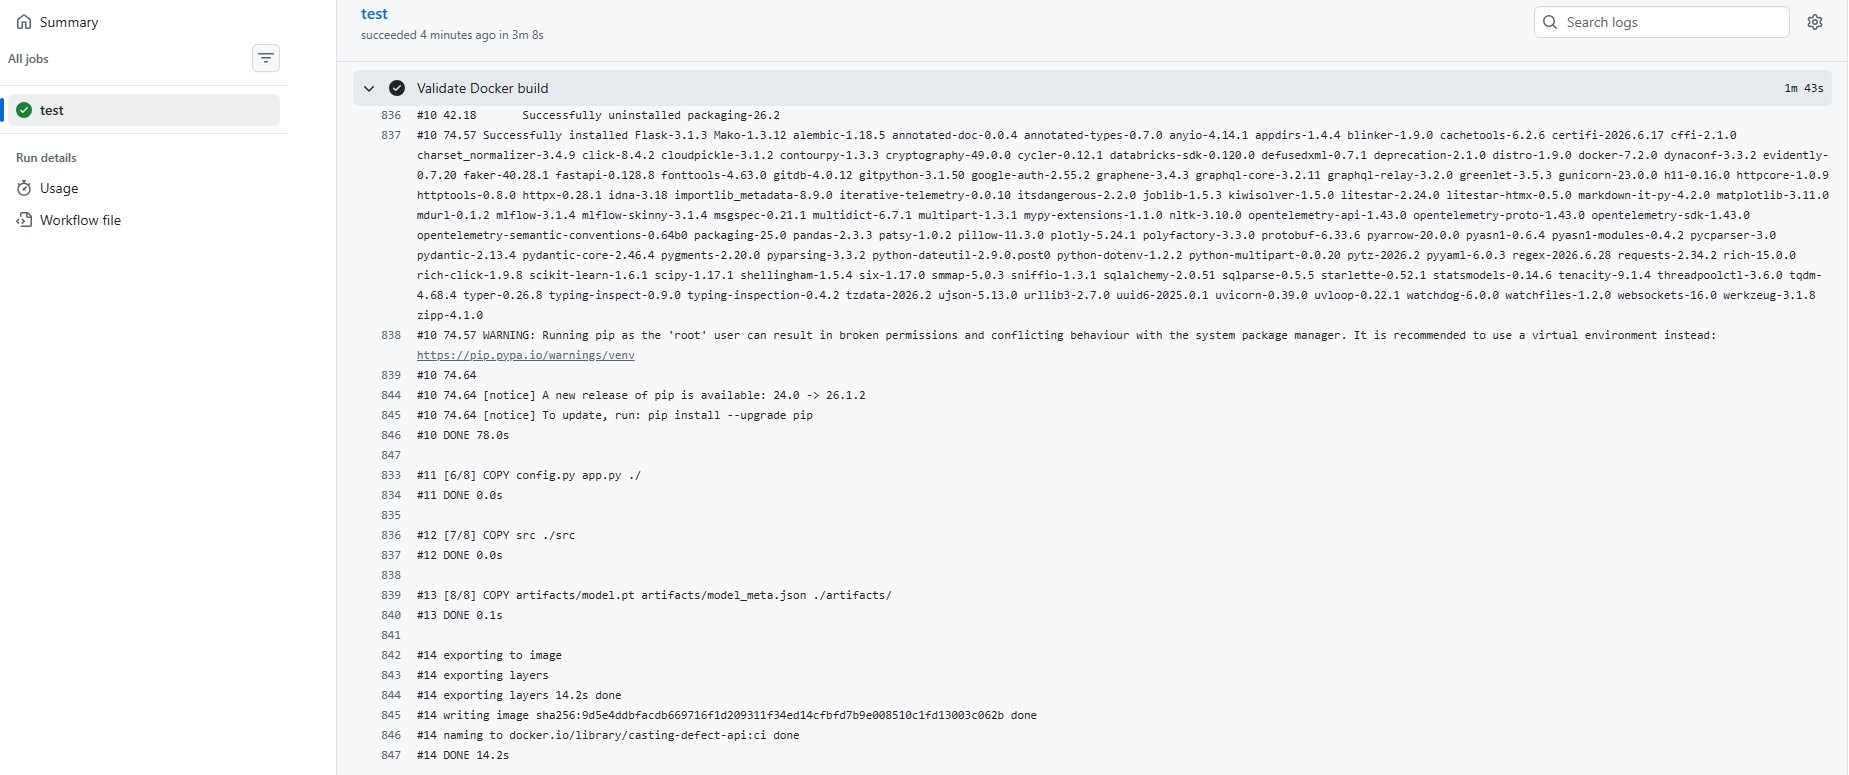

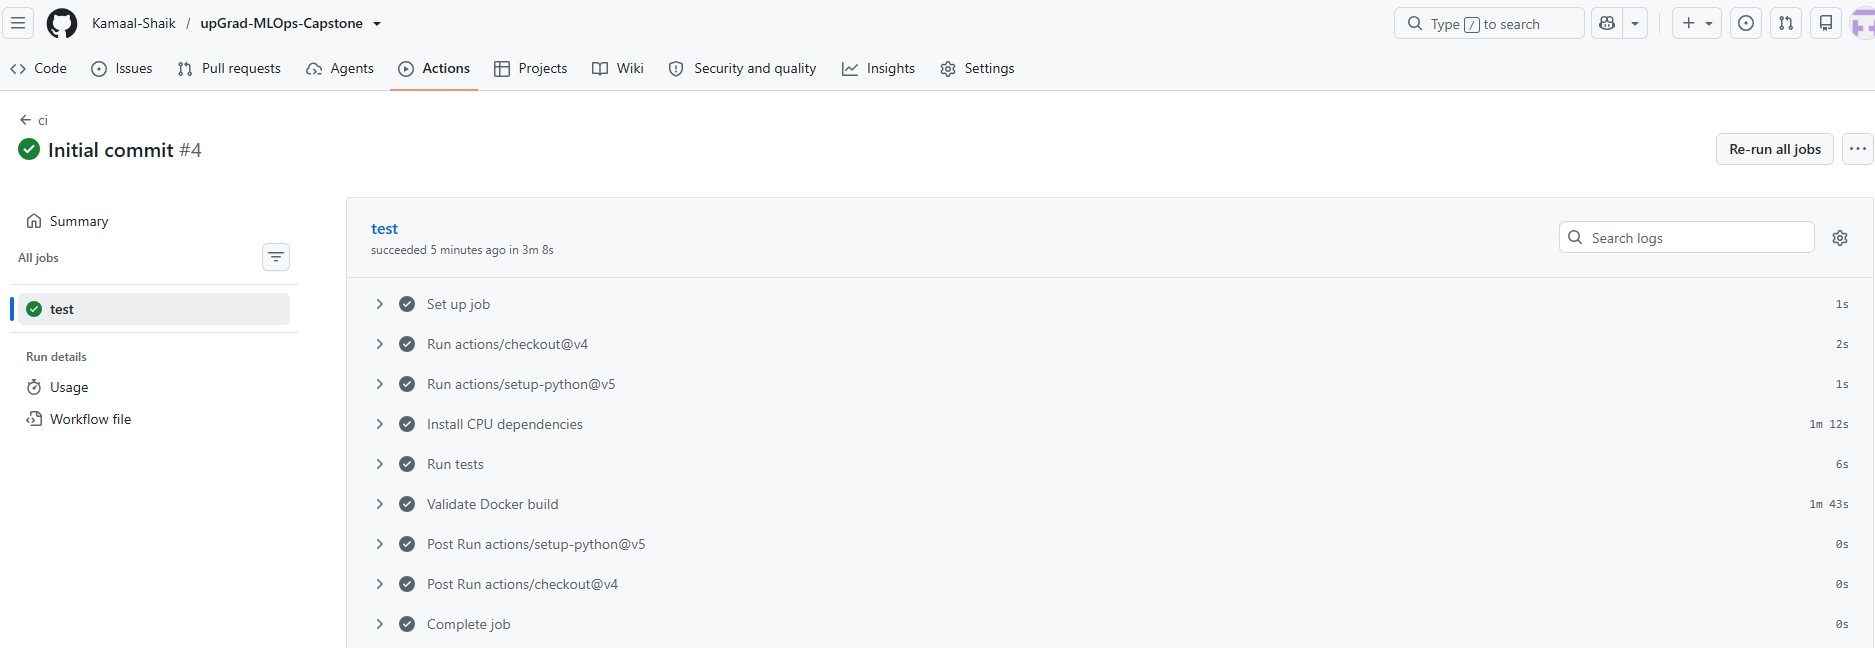

- Pytest output above shows all tests passing.
- Screenshot: GitHub Actions run is green (tests + Docker build succeeded).
- Screenshot: Docker build completed successfully.

This demonstrates reproducible containerisation and CI/CD automation.
